In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns 

In [3]:
df = pd.read_csv("telecom_clientes.csv")

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   Churn             7043 non-null   str    
 2   Gender            7043 non-null   str    
 3   SeniorCitizen     7043 non-null   int64  
 4   Partner           7043 non-null   str    
 5   Dependents        7043 non-null   str    
 6   Tenure            7043 non-null   int64  
 7   PhoneService      7043 non-null   str    
 8   MultipleLines     7043 non-null   str    
 9   InternetService   7043 non-null   str    
 10  OnlineSecurity    7043 non-null   str    
 11  OnlineBackup      7043 non-null   str    
 12  DeviceProtection  7043 non-null   str    
 13  TechSupport       7043 non-null   str    
 14  StreamingTV       7043 non-null   str    
 15  StreamingMovies   7043 non-null   str    
 16  Contract          7043 non-null   str    
 17  Paperl

In [5]:
#Buscar valores vacíos
valores_vacios = (df['ChargesTotal'] == ' ').sum()

In [6]:
valores_vacios

np.int64(0)

In [7]:
#Buscar valores nulos
df.isna().sum()

customerID           0
Churn                0
Gender               0
SeniorCitizen        0
Partner              0
Dependents           0
Tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
ChargesMonthly       0
ChargesTotal        11
CuentasDiarias       0
dtype: int64

In [8]:
#Eliminar valores nulos
df = df.dropna()

In [9]:
#Comprobar que fueron eliminados
df.isna().sum()

customerID          0
Churn               0
Gender              0
SeniorCitizen       0
Partner             0
Dependents          0
Tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
ChargesMonthly      0
ChargesTotal        0
CuentasDiarias      0
dtype: int64

In [10]:
#Porcentaje de clientes que hicieron churn
proporcion_evasion = df['Churn'].value_counts(normalize=True).to_frame()

In [11]:
proporcion_evasion

,proportion
Churn,
no,0.734215
yes,0.265785


In [12]:
round(proporcion_evasion.loc['yes'],2)

proportion    0.27
Name: yes, dtype: float64

In [13]:
tasa_pago = pd.crosstab(df["Gender"], df["Churn"], normalize=True)
    
tasa_pago.sort_values(by='yes', ascending=True, inplace=True)

In [14]:
tasa_pago.info()

<class 'pandas.DataFrame'>
Index: 2 entries, male to female
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   no      2 non-null      float64
 1   yes     2 non-null      float64
dtypes: float64(2)
memory usage: 59.0 bytes


In [15]:
tasa_pago.index

Index(['male', 'female'], dtype='str', name='Gender')

In [16]:
tasa_pago['yes']

Gender
male      0.132253
female    0.133532
Name: yes, dtype: float64

In [17]:
tasa_pago = pd.crosstab(df['Gender'], df["Churn"], normalize='index')
    
tasa_pago.sort_values(by='yes', ascending=True, inplace=True)

In [18]:
tasa_pago.info()

<class 'pandas.DataFrame'>
Index: 2 entries, male to female
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   no      2 non-null      float64
 1   yes     2 non-null      float64
dtypes: float64(2)
memory usage: 59.0 bytes


In [19]:
tasa_pago

Churn,no,yes
Gender,,
male,0.737954,0.262046
female,0.730405,0.269595


In [20]:
tasa_pago.index

Index(['male', 'female'], dtype='str', name='Gender')

In [21]:
for categoria in tasa_pago.index:
    tasa_categoria = tasa_pago.loc[categoria, 'yes']

    print(tasa_categoria)

0.26204564666103125
0.2695951765719208


In [22]:
df['SeniorCitizen'] = np.where(df['SeniorCitizen'] == 1, 'Mayor que 65', 'Menor que 65')

In [23]:
df['SeniorCitizen']

0       Menor que 65
1       Menor que 65
2       Menor que 65
3       Mayor que 65
4       Mayor que 65
            ...     
7038    Menor que 65
7039    Menor que 65
7040    Menor que 65
7041    Menor que 65
7042    Menor que 65
Name: SeniorCitizen, Length: 7032, dtype: str

In [24]:
servicios = df[['PhoneService', 'MultipleLines',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies']]

servicios_columnas = ['PhoneService', 
                      'MultipleLines', 
                      'OnlineSecurity', 
                      'OnlineBackup', 
                      'DeviceProtection',
                       'TechSupport', 
                       'StreamingTV', 
                       'StreamingMovies']

servicios[servicios_columnas] = np.where(servicios[servicios_columnas] == 'yes', 1, 0)

servicios['InternetService'] = np.where((df['InternetService'] == 'dsl') | (df['InternetService'] == 'fiber optic'), 1, 0)

servicios['Churn'] = np.where(df['Churn'] == 'yes', 1, 0)

servicios_columnas.append('InternetService')

servicios['numero_servicios'] = servicios[servicios_columnas].sum(axis=1)

In [25]:
servicios

,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetService,Churn,numero_servicios
0,1,0,0,1,0,1,1,0,1,0,5
1,1,1,0,0,0,0,0,1,1,0,4
2,1,0,0,0,1,0,0,0,1,1,3
3,1,0,0,1,1,0,1,1,1,1,6
4,1,0,0,0,0,1,1,0,1,1,4
...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,0,0,1,0,0,1,0,4
7039,1,1,0,0,0,0,0,1,1,1,4
7040,1,0,0,1,0,0,0,0,1,0,3
7041,1,0,1,0,1,1,0,1,1,0,6


<Axes: xlabel='numero_servicios', ylabel='Count'>

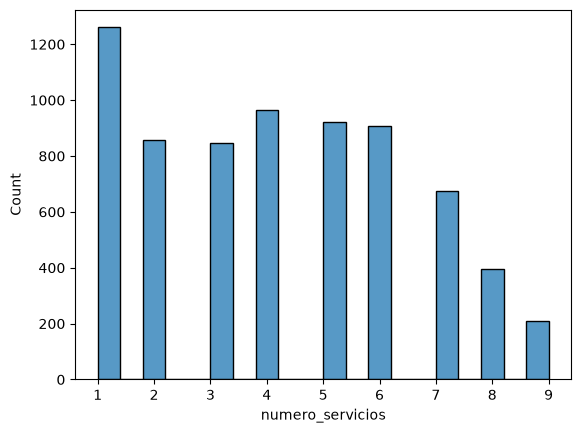

In [26]:
sns.histplot(data=servicios['numero_servicios'])


In [27]:
churn_servicios = pd.crosstab(servicios['numero_servicios'], servicios['Churn'], normalize='index')

churn_servicios.rename({0:'No', 1:'Yes'}, axis=1, inplace=True)

In [28]:
churn_servicios

Churn,No,Yes
numero_servicios,,
1,0.890476,0.109524
2,0.689615,0.310385
3,0.550827,0.449173
4,0.635233,0.364767
5,0.686211,0.313789
6,0.743929,0.256071
7,0.774481,0.225519
8,0.875949,0.124051
9,0.947115,0.052885


In [29]:
servicios_tenure = pd.DataFrame()
servicios_tenure['n_servicios'] = servicios['numero_servicios']
servicios_tenure['tenure'] = df['Tenure']
servicios_tenure['churn'] = df['Churn']


corr_servicios_tenure = servicios_tenure[['tenure', 'n_servicios']].corr()

In [30]:
servicios_tenure = servicios_tenure.sort_values(by='churn', ascending=True)

In [42]:
corr_servicios_tenure.iloc[0,1]

np.float64(0.4743698007260296)

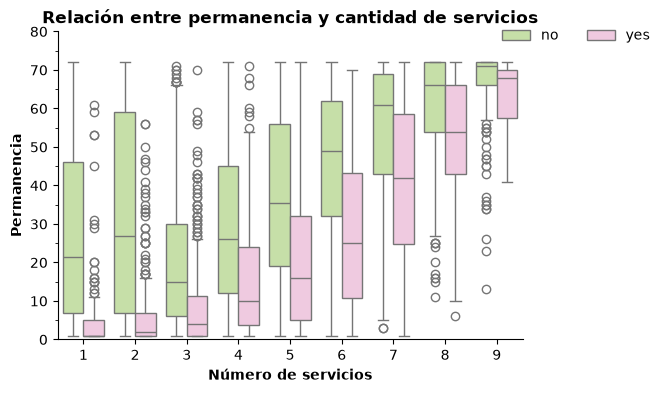

In [32]:
fig, ax  = plt.subplots(figsize=(6,4))

sns.boxplot(servicios_tenure, x='n_servicios', y='tenure', hue='churn', palette='PiYG_r', ax=ax)

ax.set_title('Relación entre permanencia y cantidad de servicios', fontsize=12, fontweight='bold')
ax.set_xlabel('Número de servicios', fontsize=10, fontweight='bold')
ax.set_ylabel('Permanencia', fontsize=10, fontweight='bold')

ax.set_ylim(0,80)
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))

ax.legend(loc='upper right', bbox_to_anchor=(1.30,1.05), ncols=2, frameon=False)

ax.spines[['top', 'right']].set_visible(False)

plt.show()

In [33]:
facturacion_permanencia = pd.DataFrame()

facturacion_permanencia['total_facturado'] = df['ChargesTotal']
facturacion_permanencia['tenure'] = df['Tenure']

facturacion_permanencia.corr()

,total_facturado,tenure
total_facturado,1.00000,0.82588
tenure,0.82588,1.00000


In [34]:
facturacion_permanencia['churn'] = df['Churn']

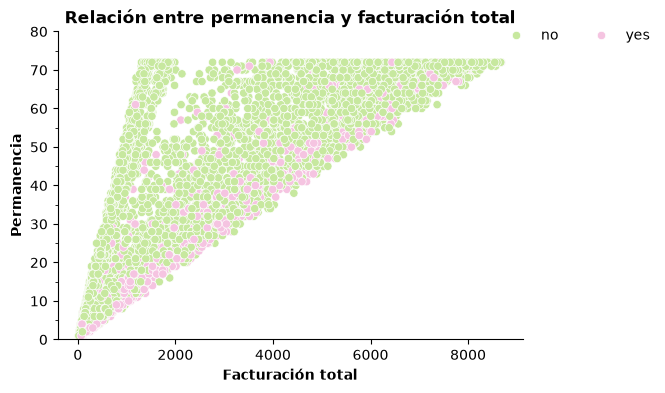

In [35]:
fig, ax  = plt.subplots(figsize=(6,4))

sns.scatterplot(facturacion_permanencia, x='total_facturado', y='tenure', hue='churn', palette='PiYG_r', ax=ax)

ax.set_title('Relación entre permanencia y facturación total', fontsize=12, fontweight='bold')
ax.set_xlabel('Facturación total', fontsize=10, fontweight='bold')
ax.set_ylabel('Permanencia', fontsize=10, fontweight='bold')

ax.set_ylim(0,80)
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))

ax.legend(loc='upper right', bbox_to_anchor=(1.30,1.05), ncols=2, frameon=False)

ax.spines[['top', 'right']].set_visible(False)

plt.show()